# Policy Gradient Methods: REINFORCE, REINFORCE with Baseline, and Actor-Critic

**Assignment:** implement three policy-gradient algorithms from Sutton & Barto (Chapter 13) in PyTorch, run each on five Gymnasium environments with a neural-network policy, and compare their learning curves (in the style of Figure 13.2).

**Environments:** CartPole-v1, Acrobot-v1, LunarLander-v3, Pendulum-v1 (continuous actions), CliffWalking-v1.

**Algorithms:**
1. **REINFORCE** (Monte-Carlo policy gradient, S&B §13.3)
2. **REINFORCE with baseline** (learned state-value baseline, S&B §13.4)
3. **One-step Actor-Critic** (episodic, S&B §13.5)

Each curve is the mean over **5 random seeds**; the shaded band is ±1 standard deviation across seeds. Both are smoothed with a 10-episode moving average. The y-axis is the **true (unscaled) undiscounted episode return** $G_0$.

## 1. Setup

In [1]:
# !pip install -q "gymnasium[box2d]" torch matplotlib numpy

## 2. Implementation


In [2]:
import numpy as np, torch, torch.nn as nn, gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Categorical, Normal

torch.set_num_threads(1)

class OneHot(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.n = env.observation_space.n
        self.observation_space = gym.spaces.Box(0, 1, (self.n,), np.float32)
    def observation(self, o):
        v = np.zeros(self.n, np.float32); v[o] = 1.0
        return v

def make_env(name, max_steps):
    env = gym.make(name, max_episode_steps=max_steps)
    if isinstance(env.observation_space, gym.spaces.Discrete):
        env = OneHot(env)
    return env

### Per-environment configuration
Network sizes and learning rates are chosen per environment. Larger hidden layers are used for LunarLander; the one-hot gridworld uses a single small hidden layer.

In [3]:
CONFIGS = {
    "CartPole-v1":     dict(episodes=500,  hidden=(64, 64),   lr_pi=1e-3, lr_v=1e-3, gamma=0.99, reward_scale=0.01, max_steps=500),
    "Acrobot-v1":      dict(episodes=500,  hidden=(64, 64),   lr_pi=1e-3, lr_v=5e-3, gamma=0.99, reward_scale=0.1,  max_steps=500),
    "LunarLander-v3":  dict(episodes=1000, hidden=(128, 128), lr_pi=5e-4, lr_v=1e-3, gamma=0.99, reward_scale=0.01, max_steps=1000),
    "Pendulum-v1":     dict(episodes=1500, hidden=(64, 64),   lr_pi=1e-3, lr_v=1e-3, gamma=0.99, reward_scale=0.1,  max_steps=200),
    "CliffWalking-v1": dict(episodes=200,  hidden=(32,),      lr_pi=3e-3, lr_v=3e-3, gamma=0.99, reward_scale=0.05, max_steps=200),
}
N_SEEDS = 5

### Networks

In [4]:
def mlp(inp, hidden, out):
    layers, d = [], inp
    for h in hidden:
        layers += [nn.Linear(d, h), nn.Tanh()]; d = h
    layers.append(nn.Linear(d, out))
    return nn.Sequential(*layers)

class Policy(nn.Module):
    def __init__(self, env, hidden):
        super().__init__()
        obs_dim = env.observation_space.shape[0]
        self.discrete = isinstance(env.action_space, gym.spaces.Discrete)
        if self.discrete:
            self.net = mlp(obs_dim, hidden, env.action_space.n)
        else:
            self.net = mlp(obs_dim, hidden, env.action_space.shape[0])
            self.log_std = nn.Parameter(torch.full((env.action_space.shape[0],), -0.5))
            self.low = torch.as_tensor(env.action_space.low)
            self.high = torch.as_tensor(env.action_space.high)
    def dist(self, s):
        out = self.net(s)
        if self.discrete:
            return Categorical(logits=out)
        return Normal(out, self.log_std.exp())
    def log_prob(self, d, a):
        lp = d.log_prob(a)
        return lp if self.discrete else lp.sum(-1)
    def to_env(self, a):
        if self.discrete:
            return int(a.item())
        return torch.clamp(a, self.low, self.high).numpy()

def make_value(env, hidden):
    return mlp(env.observation_space.shape[0], hidden, 1)

### The three algorithms
- **REINFORCE:** roll out a full episode, compute returns-to-go $G_t$, and ascend $\gamma^t G_t \nabla\log\pi(A_t|S_t)$ once per episode.
- **REINFORCE with baseline:** same, but use $\delta_t = G_t - \hat v(S_t)$ in place of $G_t$; the value network is regressed towards $G_t$ with MSE.
- **Actor-Critic (one-step):** update after every step with the TD error $\delta = R + \gamma \hat v(S') - \hat v(S)$. The critic is trained on the TD target and the actor ascends $I\,\delta\,\nabla\log\pi(A|S)$ with $I \leftarrow \gamma I$. We bootstrap through time-limit truncation and use $\hat v(S')=0$ only for true termination.

In [5]:
def rollout(env, pi):
    obs, _ = env.reset()
    S, A, R, done = [], [], [], False
    while not done:
        s = torch.as_tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            a = pi.dist(s).sample()
        obs, r, term, trunc, _ = env.step(pi.to_env(a))
        S.append(s); A.append(a); R.append(r)
        done = term or trunc
    return torch.stack(S), torch.stack(A), R

def returns_to_go(R, gamma, scale):
    G, out = 0.0, []
    for r in reversed(R):
        G = r * scale + gamma * G
        out.append(G)
    return torch.tensor(out[::-1], dtype=torch.float32)

def train_episodic(env, cfg, use_baseline, seed):
    pi = Policy(env, cfg["hidden"])
    opt_pi = torch.optim.Adam(pi.parameters(), lr=cfg["lr_pi"])
    if use_baseline:
        V = make_value(env, cfg["hidden"])
        opt_v = torch.optim.Adam(V.parameters(), lr=cfg["lr_v"])
    scores = []
    for ep in range(cfg["episodes"]):
        S, A, R = rollout(env, pi)
        scores.append(sum(R))
        G = returns_to_go(R, cfg["gamma"], cfg["reward_scale"])
        disc = cfg["gamma"] ** torch.arange(len(R), dtype=torch.float32)
        if use_baseline:
            v = V(S).squeeze(-1)
            delta = (G - v).detach()
            loss_v = ((G - v) ** 2).mean()
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
        else:
            delta = G
        logp = pi.log_prob(pi.dist(S), A)
        loss_pi = -(disc * delta * logp).mean()
        opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()
    return scores

def train_actor_critic(env, cfg, seed):
    pi = Policy(env, cfg["hidden"])
    V = make_value(env, cfg["hidden"])
    opt_pi = torch.optim.Adam(pi.parameters(), lr=cfg["lr_pi"])
    opt_v = torch.optim.Adam(V.parameters(), lr=cfg["lr_v"])
    gamma, scale = cfg["gamma"], cfg["reward_scale"]
    scores = []
    for ep in range(cfg["episodes"]):
        obs, _ = env.reset()
        I, total, done = 1.0, 0.0, False
        while not done:
            s = torch.as_tensor(obs, dtype=torch.float32)
            d = pi.dist(s)
            a = d.sample()
            logp = pi.log_prob(d, a)
            obs, r, term, trunc, _ = env.step(pi.to_env(a))
            total += r
            s2 = torch.as_tensor(obs, dtype=torch.float32)
            with torch.no_grad():
                v_next = torch.zeros(1) if term else V(s2)
            target = r * scale + gamma * v_next
            v = V(s)
            delta = (target - v).detach()
            loss_v = ((target - v) ** 2).mean()
            loss_pi = -(I * delta * logp).sum()
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
            opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()
            I *= gamma
            done = term or trunc
        scores.append(total)
    return scores

ALGOS = {
    "REINFORCE":               lambda env, cfg, seed: train_episodic(env, cfg, False, seed),
    "REINFORCE with baseline": lambda env, cfg, seed: train_episodic(env, cfg, True, seed),
    "Actor-Critic":            lambda env, cfg, seed: train_actor_critic(env, cfg, seed),
}

### Running experiments and plotting


In [6]:
def run_one(env_name, algo_name, seed):
    cfg = CONFIGS[env_name]
    torch.manual_seed(seed); np.random.seed(seed)
    env = make_env(env_name, cfg["max_steps"])
    env.reset(seed=seed); env.action_space.seed(seed)
    return ALGOS[algo_name](env, cfg, seed)

def run_env(env_name, n_seeds=N_SEEDS):
    results = {}
    for algo in ALGOS:
        runs = [run_one(env_name, algo, s) for s in range(n_seeds)]
        results[algo] = np.array(runs)
        print(f"{env_name} | {algo:25s} | Average return over the last 50 rounds: {results[algo][:, -50:].mean():.1f}")
    return results

def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

def plot_env(env_name, results):
    colors = {"REINFORCE": "tab:red", "REINFORCE with baseline": "tab:green", "Actor-Critic": "tab:blue"}
    plt.figure(figsize=(7, 4.5))
    for algo, arr in results.items():
        m, sd = arr.mean(0), arr.std(0)
        ms, sds = smooth(m), smooth(sd)
        x = np.arange(1, len(ms) + 1)
        plt.plot(x, ms, label=algo, color=colors[algo])
        plt.fill_between(x, ms - sds, ms + sds, color=colors[algo], alpha=0.15)
    plt.xlabel("Episode"); plt.ylabel(f"Total reward on episode (G0)\naveraged over {arr.shape[0]} runs")
    plt.title(env_name); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f"{env_name}.png", dpi=150); plt.show()

In [7]:
import pickle, os
os.makedirs("results", exist_ok=True)

def run_env_cached(name, n_seeds=N_SEEDS):
    path = f"results/{name}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    res = run_env(name, n_seeds)
    pickle.dump(res, open(path, "wb"))
    return res

ALL = {}

## 3. Experiments and results

### CartPole-v1

CartPole-v1 | REINFORCE                 | Average return over the last 50 rounds: 160.1
CartPole-v1 | REINFORCE with baseline   | Average return over the last 50 rounds: 447.3
CartPole-v1 | Actor-Critic              | Average return over the last 50 rounds: 160.3


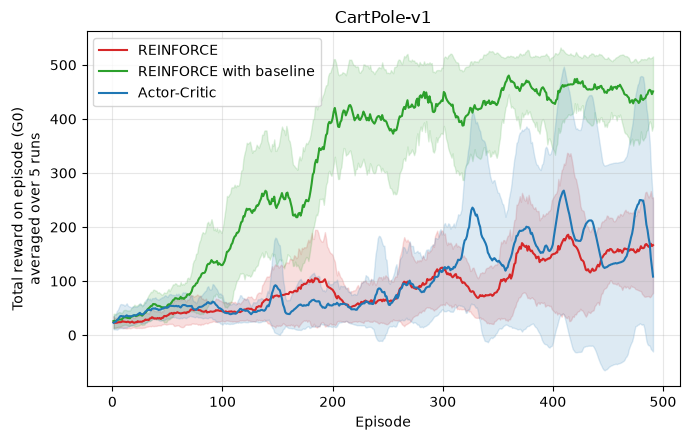

In [8]:
ALL["CartPole-v1"] = run_env_cached("CartPole-v1")
plot_env("CartPole-v1", ALL["CartPole-v1"])

**CartPole-v1** (discrete, max return 500; 500 episodes)

REINFORCE with baseline is clearly the best here: it rises steadily from ~25 to a last-50-episode mean of **447.3**, while plain REINFORCE only reaches **160.1**. This is the textbook picture of variance reduction: with the same step size, the baseline makes the gradient estimate far less noisy, so learning is much faster . Actor-Critic improves in places but is very unstable, with large swings and a wide band across seeds; its last-50-episode mean (**160.3**) is essentially tied with plain REINFORCE and far below the baseline method.

### Acrobot-v1

Acrobot-v1 | REINFORCE                 | Average return over the last 50 rounds: -474.8
Acrobot-v1 | REINFORCE with baseline   | Average return over the last 50 rounds: -87.7
Acrobot-v1 | Actor-Critic              | Average return over the last 50 rounds: -417.4


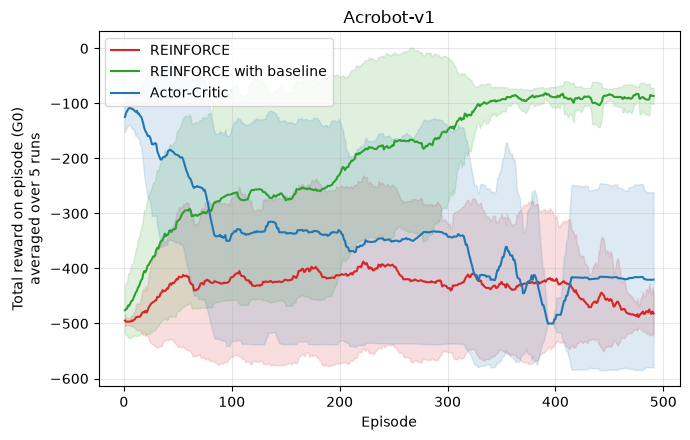

In [9]:
ALL["Acrobot-v1"] = run_env_cached("Acrobot-v1")
plot_env("Acrobot-v1", ALL["Acrobot-v1"])

**Acrobot-v1** (discrete, reward −1 per step, limit 500; 500 episodes)

REINFORCE with baseline learns reliably and reaches a last-50-episode mean of **−87.7**, whereas plain REINFORCE stays near the −500 time-out for most of training (**−474.8**). Actor-Critic behaves differently: its first averaged points are already much better than the other methods (≈ −110 to −125). A plausible reason is that it updates after every step, so it has already made many updates by the end of the first episode, but this is not verified here. It then degrades, so its final performance is much worse than the baseline method. We did not diagnose the cause; likely contributors are the interaction between a fast-moving critic and per-step actor updates without gradient clipping.

### LunarLander-v3

C:\Users\16174\AppData\Local\Programs\Python\Python313\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


LunarLander-v3 | REINFORCE                 | Average return over the last 50 rounds: -57.6
LunarLander-v3 | REINFORCE with baseline   | Average return over the last 50 rounds: -78.7
LunarLander-v3 | Actor-Critic              | Average return over the last 50 rounds: -74.3


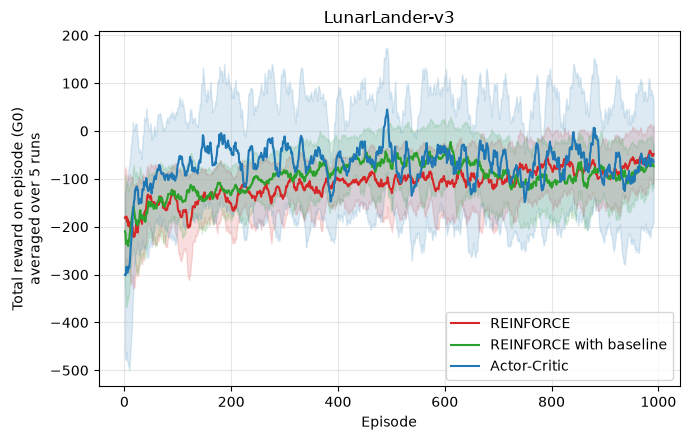

In [10]:
ALL["LunarLander-v3"] = run_env_cached("LunarLander-v3")
plot_env("LunarLander-v3", ALL["LunarLander-v3"])

**LunarLander-v3** (discrete, 1000 episodes; a score of ≈ 200 is considered solved)

None of the three algorithms solves the task within 1000 episodes: the last-50-episode means are **−57.6** (REINFORCE), **−78.7** (baseline) and **−74.3** (Actor-Critic). Actor-Critic is ahead early on (it is around −100 to 0 for the first few hundred episodes while the others are around −150), but it is very noisy, and by the end the three curves are not distinguishable given the overlapping bands (plain REINFORCE even has the highest final mean, by a small margin). This environment would likely need many more episodes and/or better tuning (e.g. larger batches, return normalization, entropy regularization) to reach good landings.

### Pendulum-v1

Pendulum-v1 | REINFORCE                 | Average return over the last 50 rounds: -1488.8
Pendulum-v1 | REINFORCE with baseline   | Average return over the last 50 rounds: -1333.4
Pendulum-v1 | Actor-Critic              | Average return over the last 50 rounds: -1399.5


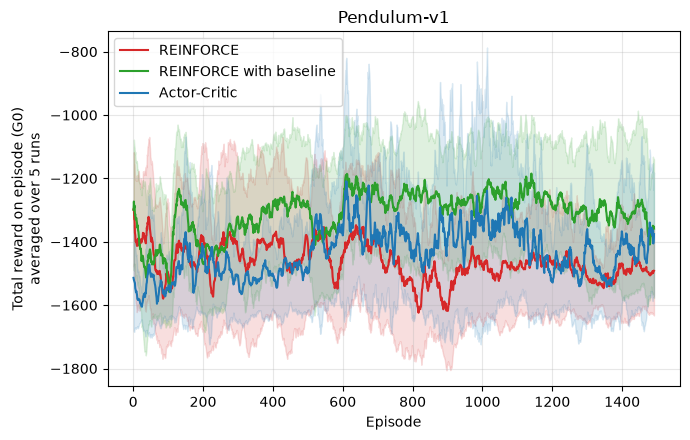

In [11]:
ALL["Pendulum-v1"] = run_env_cached("Pendulum-v1")
plot_env("Pendulum-v1", ALL["Pendulum-v1"])

**Pendulum-v1** (continuous action, 1500 episodes of 200 steps)

This is the weakest result: no algorithm clearly learns a swing-up policy within the budget. Returns stay roughly between −1200 and −1600 (a good policy would score far higher). Last-50-episode means: REINFORCE **−1488.8**, REINFORCE with baseline **−1333.4**, Actor-Critic **−1399.5**. The baseline method is slightly better on average, but the bands overlap heavily, so these differences are weak evidence. Plausible reasons are the continuous Gaussian policy with a learnable but untuned exploration scale, the large and dense reward scale, and the long horizon; policy-gradient methods without further tricks (normalization, clipping, entropy, larger batches) are known to be sample-inefficient here. We report this honestly as *not converged* under our budget.

### CliffWalking-v1

CliffWalking-v1 | REINFORCE                 | Average return over the last 50 rounds: -246.7
CliffWalking-v1 | REINFORCE with baseline   | Average return over the last 50 rounds: -256.2
CliffWalking-v1 | Actor-Critic              | Average return over the last 50 rounds: -90.3


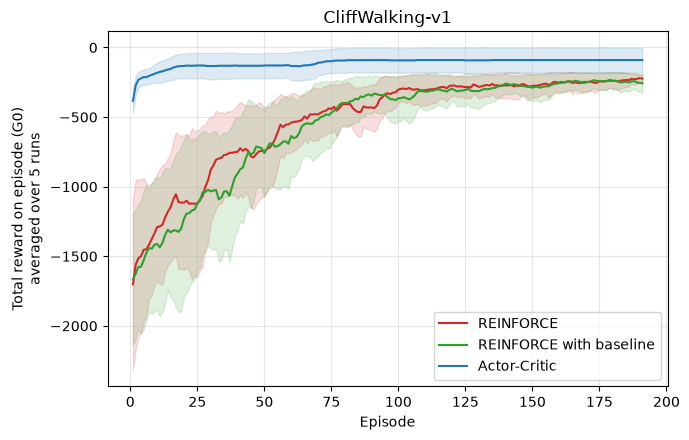

In [12]:
ALL["CliffWalking-v1"] = run_env_cached("CliffWalking-v1")
plot_env("CliffWalking-v1", ALL["CliffWalking-v1"])

**CliffWalking-v1** (one-hot discrete state; 200 episodes, 200-step limit)

This is the closest analogue to the book's short-corridor example. Actor-Critic learns far faster than the Monte-Carlo methods: it reaches about −90 (last-50 mean **−90.3**) within the first few episodes and stays there with a narrow band, whereas REINFORCE and REINFORCE with baseline start near −1700 and slowly improve to **−246.7** and **−256.2** respectively by the end. Unlike CartPole and Acrobot, the baseline gives **no visible benefit** over plain REINFORCE here (the curves are nearly the same; the baseline is even marginally slower at the start, plausibly because the value network first has to learn to predict returns). None of the methods reaches the optimal path return (−13) on average, since averages include exploratory episodes that fall off the cliff.

## 4. Summary

Mean return over the **last 50 episodes** of training, averaged over 5 seeds:

| Environment | REINFORCE | REINFORCE + baseline | Actor-Critic |
|---|---|---|---|
| CartPole-v1 | 160.1 | **447.3** | 160.3 |
| Acrobot-v1 | −474.8 | **−87.7** | −417.4 |
| LunarLander-v3 | −57.6 | −78.7 | −74.3 |
| Pendulum-v1 | −1488.8 | −1333.4 | −1399.5 |
| CliffWalking-v1 | −246.7 | −256.2 | **−90.3** |

**Take-aways**
1. **A learned baseline helps a lot when Monte-Carlo variance is the bottleneck**, reproducing the qualitative result of Figure 13.2. In CliffWalking, with only 200 episodes and a one-hot input, it did not help.
2. **Actor-Critic learns fastest early** on CliffWalking and Acrobot/LunarLander because it updates every step and bootstraps, but in our untuned setting it was **less stable** on CartPole and Acrobot, where bootstrapping from a changing critic and per-step updates produced collapses and large seed-to-seed variance. This is the usual bias/variance trade-off: lower variance and faster updates, at the cost of bias and instability.
3. **Hard tasks were not solved** within the episode budget with these vanilla algorithms; differences there are within noise.

**Limitations.** Only 5 seeds, so bands are wide and many differences are not statistically conclusive; only the CartPole and Acrobot baseline gains and the CliffWalking Actor-Critic gain are clearly outside the noise. Hyperparameters were hand-picked once, not swept, and not tuned separately per algorithm, so rankings may change with tuning. Explanations given for the observed behaviour are plausible hypotheses, not verified by ablation.